# Challenge Sprint 3: Preparação e divisão do dataset

**Integrantes:** Lucas Ferrari Lima (RM 563119) · Carlos Eduardo Pires Cervelli (RM 563462) · Felipe Krzyzanovski dos Santos Menezes (RM 564878) · Leonardo Lopes Oliveira (RM 565437) · Arthur de Souza Matos Dias (RM 566068) · Guilherme Carreri Giampietro (RM 565676) · Mateus Patrício Pereira (RM 564695)

**Objetivo:** preparar e organizar as imagens que serão usadas depois no treinamento de uma CNN de **identificação de espécies de plantas**: escolher a base, dividir em **Train / Validation / Test**, checar balanceamento, comparar os três conjuntos e definir como as imagens serão padronizadas. *Neste sprint a CNN não é treinada.*

**Fluxo de preparação:**

`Imagem original → Resize / Crop / Padding → Normalização → Imagem padronizada → CNN`

| # | Seção | Requisito do sprint |
|---|---|---|
| 1 | Dataset escolhido | imagens, classes, exemplos |
| 2 | Validação e limpeza | arquivos × rótulos, duplicatas (vazamento) |
| 3 | Divisão dos dados | Train / Validation / Test |
| 4 | Balanceamento das classes | quantidade por classe e desbalanceamento |
| 5 | Medição das imagens | resolução, canais, intervalo dos pixels |
| 6 | Comparação Train × Val × Test | classes, média/desvio, histogramas, canais RGB |
| 7 | Dimensão das imagens e sessões de captura | resoluções, câmeras, risco de vazamento |
| 8 | Padronização para a CNN | resize, crop, padding e normalização |
| 9 | Análise final | as 4 perguntas do sprint |

> **Como executar:** *Run All*. Requer `numpy pandas matplotlib pillow scipy scikit-learn` (e `gdown` só se a base ainda não estiver na pasta `data/`). A primeira execução baixa a base (~470 MB) e copia as imagens para `dataset/`.

In [1]:
import hashlib, math, os, re, shutil, time, urllib.request, warnings, zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from scipy import stats

# ── Configuração do experimento ─────────────────────────────────────────────
SEED = 42                       # reprodutibilidade do split
RATIOS = (0.70, 0.15, 0.15)     # train / val / test
SIZE = 224                      # lado da entrada da CNN
DATA_DIR = Path("data")         # labels.csv e images/ (DeepWeeds)
DATASET_DIR = Path("dataset")   # saída: dataset/{train,val,test}/<Classe>/
COPY_FILES = True               # False = só calcula, sem copiar as imagens

# ── Estilo dos gráficos (uma cor por entidade em todo o notebook) ───────────
SPLIT_C = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
SPLIT_N = {"train": "Train", "val": "Validation", "test": "Test"}
C_SPECIES, C_NEG = "#4a3aa7", "#898781"      # espécie-alvo (violeta) vs. Negative (cinza)
SPLITS = ("train", "val", "test")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": False, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})


def br(n):        # 5152 -> "5.152"
    return f"{int(round(n)):,}".replace(",", ".")


def pc(x, k=1):   # 0.3234 -> "32,3%"
    return f"{x * 100:.{k}f}%".replace(".", ",")


def num(x, k=2):  # 1.234 -> "1,23"
    return f"{x:.{k}f}".replace(".", ",")


def up(x, k=2):   # arredonda p/ cima: limites superiores nunca ficam otimistas
    return num(math.ceil(x * 10**k) / 10**k, k)


def down(x, k=2): # arredonda p/ baixo: limites inferiores nunca ficam otimistas
    return num(math.floor(x * 10**k) / 10**k, k)


def kind_c(c):
    return C_NEG if c == "Negative" else C_SPECIES

### Funções de apoio

Leitura do `labels.csv`, nome do arquivo (data, hora e câmera), remoção de duplicatas, split estratificado, recortes (`crop`), normalização e pesos de classe ficam neste bloco. É o **mesmo código coberto por 47 testes automatizados** (`tests/`), escritos antes da implementação (TDD).

In [2]:
"""Funções puras de preparação do dataset (rótulos, split, padronização)."""
import hashlib
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

SPLITS = ("train", "val", "test")


# ---------- rótulos ----------

def parse_label(filename):
    """'Abyssinian_1.jpg' -> ('gato', 'Abyssinian'); 'beagle_42.jpg' -> ('cao', 'beagle').

    Convenção do Oxford-IIIT Pet: raças de gato começam com maiúscula.
    """
    breed = Path(filename).stem.rsplit("_", 1)[0]
    return ("gato" if breed[0].isupper() else "cao"), breed


# ---------- duplicatas ----------

def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


def drop_duplicates(paths):
    """Mantém a primeira ocorrência de cada conteúdo idêntico. Retorna (mantidos, removidos)."""
    seen, kept, removed = set(), [], []
    for p in paths:
        digest = file_md5(p)
        if digest in seen:
            removed.append(p)
        else:
            seen.add(digest)
            kept.append(p)
    return kept, removed


# ---------- split estratificado ----------

def assign_splits(strata, ratios=(0.70, 0.15, 0.15), seed=42):
    """Devolve o nome do split ('train'/'val'/'test') de cada item, estratificado por `strata`."""
    if abs(sum(ratios) - 1.0) > 1e-9:
        raise ValueError(f"as razões devem somar 1, recebido {sum(ratios)}")
    train_r, val_r, test_r = ratios
    idx = np.arange(len(strata))
    strata = np.asarray(strata)

    train_idx, rest_idx = train_test_split(
        idx, test_size=val_r + test_r, stratify=strata, random_state=seed
    )
    val_idx, test_idx = train_test_split(
        rest_idx,
        test_size=test_r / (val_r + test_r),
        stratify=strata[rest_idx],
        random_state=seed,
    )

    out = [None] * len(strata)
    for name, members in zip(SPLITS, (train_idx, val_idx, test_idx)):
        for i in members:
            out[i] = name
    return out


# ---------- padronização das imagens ----------

def load_rgb(path):
    """Abre qualquer imagem (JPEG, PNG/GIF disfarçado, L, P, RGBA) como RGB de 3 canais."""
    with Image.open(path) as im:
        return im.convert("RGB")


def resize_center_crop(img, size):
    """Redimensiona o lado menor para `size` (mantém proporção) e recorta o centro size×size."""
    w, h = img.size
    scale = size / min(w, h)
    nw, nh = max(size, round(w * scale)), max(size, round(h * scale))
    img = img.resize((nw, nh), Image.BICUBIC)
    left, top = (nw - size) // 2, (nh - size) // 2
    return img.crop((left, top, left + size, top + size))


def resize_pad(img, size, fill=(0, 0, 0)):
    """Redimensiona o lado maior para `size` (mantém proporção) e completa com `fill` (letterbox)."""
    w, h = img.size
    scale = size / max(w, h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    img = img.resize((nw, nh), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(img, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def resize_stretch(img, size):
    """Redimensiona direto para size×size, distorcendo a proporção."""
    return img.resize((size, size), Image.BICUBIC)


def aspect_loss(w, h):
    """Fração da área original descartada (crop) ou preenchida com vazio (padding)
    ao levar uma imagem w×h para um quadrado: 1 - lado_menor/lado_maior."""
    return 1 - min(w, h) / max(w, h)


# ---------- normalização ----------

def normalize(arr, mean, std):
    """uint8 HWC [0,255] -> float32 HWC, escalado para [0,1] e padronizado por canal."""
    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)
    if (std <= 0).any():
        raise ValueError("o desvio-padrão deve ser > 0 em todos os canais")
    x = np.asarray(arr, dtype=np.float32) / 255.0
    return ((x - mean) / std).astype(np.float32)


# ---------- DeepWeeds: nomes de arquivo, labels.csv e pesos de classe ----------

_CAPTURE_RE = re.compile(r"^(\d{8})-(\d{6})-(\d+)\.\w+$")


def parse_capture_id(filename):
    """'20170320-093423-1.jpg' -> {'date': '20170320', 'time': '093423', 'instrument': 1}.

    Padrão da DeepWeeds: YYYYMMDD-HHMMSS-ID, com ID = câmera (0 a 3) do equipamento em campo.
    """
    m = _CAPTURE_RE.match(Path(filename).name)
    if not m:
        raise ValueError(f"nome fora do padrão YYYYMMDD-HHMMSS-ID: {filename!r}")
    return {"date": m.group(1), "time": m.group(2), "instrument": int(m.group(3))}


def capture_session(filename):
    """Sessão de captura = data + instrumento; fotos da mesma sessão são muito parecidas entre si."""
    info = parse_capture_id(filename)
    return f"{info['date']}-{info['instrument']}"


def load_labels(path):
    """Lê o labels.csv (Filename, Label, Species) e acrescenta is_negative, date, instrument e session."""
    raw = pd.read_csv(path)
    missing = {"Filename", "Label", "Species"} - set(raw.columns)
    if missing:
        raise ValueError(f"colunas ausentes em {path}: {sorted(missing)}")
    df = pd.DataFrame({
        "file": raw["Filename"].astype(str),
        "label": raw["Label"].astype(int),
        "species": raw["Species"].astype(str),
    })
    df["is_negative"] = df.species.str.lower() == "negative"
    info = pd.DataFrame([parse_capture_id(f) for f in df.file])
    df["date"], df["instrument"] = info["date"], info["instrument"]
    df["session"] = df["date"] + "-" + df["instrument"].astype(str)
    return df


def balanced_class_weights(labels):
    """Peso de cada classe = n_total / (n_classes · n_classe): a classe rara pesa mais na loss."""
    counts = Counter(labels)
    if not counts:
        raise ValueError("a lista de rótulos está vazia")
    n, k = sum(counts.values()), len(counts)
    return {c: n / (k * v) for c, v in counts.items()}


def capture_seconds(filename):
    """Instante da captura, em segundos desde 2000-01-01 (inteiro; evita a unidade variável de datetime64)."""
    info = parse_capture_id(filename)
    dt = datetime.strptime(info["date"] + info["time"], "%Y%m%d%H%M%S")
    return int((dt - datetime(2000, 1, 1)).total_seconds())


def nearest_train_gap(df, time_col="t", group_cols=("session", "label"), split_col="split"):
    """Para cada foto fora do treino, o menor intervalo (s) até uma foto de treino do mesmo grupo.

    NaN = a própria foto é de treino; inf = o grupo (sessão + classe) não tem nenhuma foto de treino.
    Serve para medir o risco de vazamento por fotos quase iguais entre Train e Val/Test.
    """
    times = df[time_col].to_numpy(dtype=float)
    is_train = (df[split_col] == "train").to_numpy()
    gaps = np.full(len(df), np.nan)
    for idx in df.groupby(list(group_cols)).indices.values():
        train_t = np.sort(times[idx][is_train[idx]])
        for p in idx[~is_train[idx]]:
            if train_t.size == 0:
                gaps[p] = np.inf
                continue
            i = np.searchsorted(train_t, times[p])
            cand = []
            if i < train_t.size:
                cand.append(train_t[i] - times[p])
            if i > 0:
                cand.append(times[p] - train_t[i - 1])
            gaps[p] = min(cand)
    return gaps


# ---------- recortes sem reamostragem ----------

def center_crop(img, size):
    """Recorta o centro size×size sem reamostrar: os pixels do recorte são idênticos aos da origem."""
    w, h = img.size
    if size > w or size > h:
        raise ValueError(f"recorte {size} maior que a imagem {w}x{h}")
    left, top = (w - size) // 2, (h - size) // 2
    return img.crop((left, top, left + size, top + size))


def random_crop(img, size, rng):
    """Recorte size×size numa posição sorteada por `rng` (numpy Generator). Uso: augmentation no Train."""
    w, h = img.size
    if size > w or size > h:
        raise ValueError(f"recorte {size} maior que a imagem {w}x{h}")
    left = int(rng.integers(0, w - size + 1))
    top = int(rng.integers(0, h - size + 1))
    return img.crop((left, top, left + size, top + size))


def crop_area_lost(side, size):
    """Fração da área descartada ao recortar size×size de uma imagem quadrada de lado `side`."""
    return 1 - (size / side) ** 2

## 1. Dataset escolhido: DeepWeeds

Base pública **DeepWeeds** (Olsen et al., *Scientific Reports*, 2019): **17.509 fotos de campo** de plantas do norte da Austrália, com **8 espécies-alvo** (Chinee apple, Lantana, Parkinsonia, Parthenium, Prickly acacia, Rubber vine, Siam weed, Snake weed) e uma 9ª classe, **Negative**, com a demais vegetação do local. Licença **CC BY 4.0**.

**Por que esta base:** foco em *espécies* (o objetivo do trabalho); ~1.000 fotos por espécie; condições reais de campo (luz, fundo e ângulo variados); e um desbalanceamento genuíno (Negative ≈ 52% do total) para discutir. **Ligação com o projeto:** reconhecer espécies de vegetação é base para monitorar faixas de rodovia (Motiva); aqui, vegetação australiana serve como ponto de partida. O arquivo `labels.csv` traz `Filename, Label, Species`, e a data, a hora e a câmera vêm do próprio nome do arquivo (`AAAAMMDD-HHMMSS-ID.jpg`).

In [3]:
LABELS_URL = "https://raw.githubusercontent.com/AlexOlsen/DeepWeeds/master/labels/labels.csv"
IMAGES_GDRIVE_ID = "1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj"    # images.zip (468 MB), Google Drive do autor
LABELS, IMAGES = DATA_DIR / "labels.csv", DATA_DIR / "images"

DATA_DIR.mkdir(exist_ok=True)
if not LABELS.exists():
    urllib.request.urlretrieve(LABELS_URL, LABELS)

df = load_labels(LABELS)
if len(list(IMAGES.glob("*.jpg"))) < len(df):
    zip_path = DATA_DIR / "images.zip"
    if not zip_path.exists():
        import gdown                      # pip install gdown  (ou baixe images.zip e coloque em data/)
        gdown.download(id=IMAGES_GDRIVE_ID, output=str(zip_path), quiet=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(IMAGES)

classes = df.drop_duplicates("label").sort_values("label").species.tolist()
print(f"Rótulos (labels.csv): {br(len(df))}")
print(f"Imagens em {IMAGES}: {br(len(list(IMAGES.glob('*.jpg'))))}")
print(f"Classes: {len(classes)} -> {classes}")
df[["file", "label", "species", "date", "instrument"]].sample(6, random_state=SEED)

Rótulos (labels.csv): 17.509
Imagens em data\images: 17.509
Classes: 9 -> ['Chinee apple', 'Lantana', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed', 'Negative']


,file,label,species,date,instrument
13313,20180109-095809-1.jpg,8,Negative,20180109,1
17485,20180322-133358-1.jpg,8,Negative,20180322,1
8753,20171122-101153-1.jpg,5,Rubber vine,20171122,1
11201,20171220-091406-2.jpg,8,Negative,20171220,2
10723,20171219-113243-2.jpg,8,Negative,20171219,2
2751,20170714-150300-1.jpg,1,Lantana,20170714,1


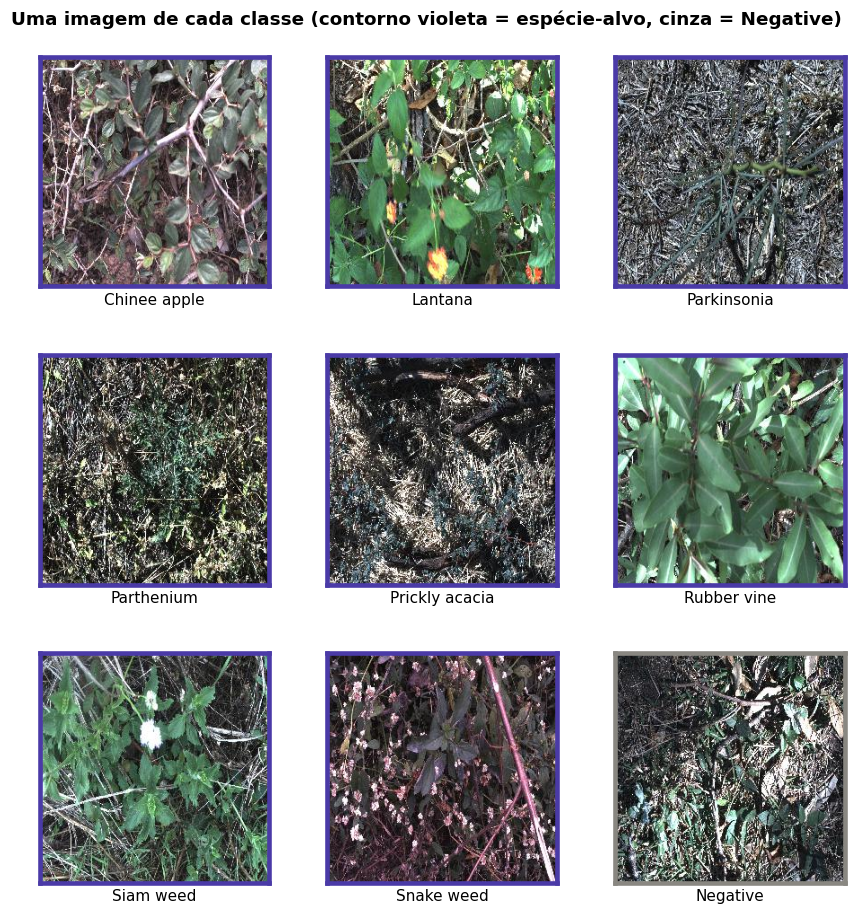

In [4]:
# Exemplos representativos: uma imagem de cada classe
rng = np.random.default_rng(3)
fig, axes = plt.subplots(3, 3, figsize=(8, 8.4))
for ax, cls in zip(axes.ravel(), classes):
    row = df[df.species == cls].iloc[int(rng.integers((df.species == cls).sum()))]
    ax.imshow(Image.open(IMAGES / row.file))
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_edgecolor(kind_c(cls)); s.set_linewidth(3)
    ax.set_xlabel(cls, fontsize=10)
fig.suptitle("Uma imagem de cada classe (contorno violeta = espécie-alvo, cinza = Negative)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); fig.subplots_adjust(top=0.93, hspace=0.3); plt.show()

## 2. Validação e limpeza

Antes de dividir: (1) todo rótulo tem arquivo e todo arquivo tem rótulo? (2) há **duplicatas exatas** (mesmo conteúdo, hash MD5)? Se a mesma foto cair em Train e Test, a avaliação fica otimista; por isso qualquer duplicata seria removida **antes** do split.

In [5]:
paths = [IMAGES / f for f in df.file]
missing = [p.name for p in paths if not p.exists()]
extra = {p.name for p in IMAGES.glob("*.jpg")} - set(df.file)
kept, removed = drop_duplicates(paths)

print(f"Arquivos ausentes (rótulo sem imagem): {len(missing)}")
print(f"Imagens sem rótulo                   : {len(extra)}")
print(f"Duplicatas exatas removidas          : {len(removed)}")
print(f"Nomes repetidos no labels.csv        : {int(df.file.duplicated().sum())}")
assert not missing and not removed
print(f"Imagens únicas restantes             : {br(len(kept))}")

Arquivos ausentes (rótulo sem imagem): 0
Imagens sem rótulo                   : 0
Duplicatas exatas removidas          : 0
Nomes repetidos no labels.csv        : 0
Imagens únicas restantes             : 17.509


## 3. Divisão dos dados: Train / Validation / Test

**Proporção 70 / 15 / 15**, split **estratificado por classe (as 9)** e `seed = 42`.

* **70% treino** (~12 mil imagens): dados de sobra para a CNN aprender folha, textura e porte da planta.
* **15% + 15%**: ~2.600 imagens em Validation e em Test dão margem de erro de ≈ ±1,1 p.p. (IC 95%) para acurácia de ~90% (±1,9 p.p. no pior caso, com acurácia de 50%).
* **Estratificar por classe** divide *cada* classe em 70/15/15, então até a menor espécie fica bem representada nos três conjuntos.
* **Validation** serve para escolher hiperparâmetros e parar o treino; **Test** só é usado uma vez, no final.

In [6]:
df["split"] = assign_splits(df.label.tolist(), ratios=RATIOS, seed=SEED)
df["folder"] = df.species.str.replace(" ", "_")
df["t"] = [capture_seconds(f) for f in df.file]          # instante da captura (s)

tab = pd.crosstab(df.split, df.species).reindex(SPLITS)[classes]
tab.insert(0, "imagens", tab.sum(axis=1))
tab.insert(1, "% do total", (tab.imagens / tab.imagens.sum() * 100).round(1))
tab.loc["TOTAL"] = tab.sum(axis=0); tab.loc["TOTAL", "% do total"] = 100.0
tab

species,imagens,% do total,Chinee apple,Lantana,Parkinsonia,Parthenium,Prickly acacia,Rubber vine,Siam weed,Snake weed,Negative
split,,,,,,,,,,,
train,12256.0,70.0,788.0,745.0,722.0,715.0,743.0,706.0,752.0,711.0,6374.0
val,2626.0,15.0,168.0,159.0,154.0,154.0,159.0,152.0,161.0,153.0,1366.0
test,2627.0,15.0,169.0,160.0,155.0,153.0,160.0,151.0,161.0,152.0,1366.0
TOTAL,17509.0,100.0,1125.0,1064.0,1031.0,1022.0,1062.0,1009.0,1074.0,1016.0,9106.0


dataset/train: 12.256 imagens
dataset/val  : 2.626 imagens
dataset/test : 2.627 imagens


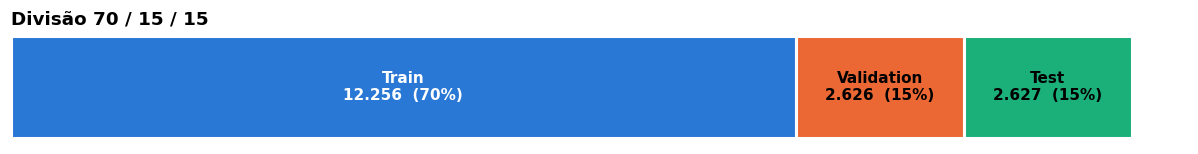

In [7]:
# Cópia física das imagens para dataset/<split>/<Classe>/  (pronto para ImageFolder / image_dataset_from_directory)
if COPY_FILES:
    for row in df.itertuples():
        dest = DATASET_DIR / row.split / row.folder
        dest.mkdir(parents=True, exist_ok=True)
        if not (dest / row.file).exists():
            shutil.copy2(IMAGES / row.file, dest / row.file)
    for s in SPLITS:
        print(f"dataset/{s:<5}: {br(sum(1 for _ in (DATASET_DIR / s).rglob('*.jpg')))} imagens")
df[["file", "label", "species", "session", "split"]].to_csv("splits.csv", index=False)

sizes = df.split.value_counts().reindex(SPLITS)
fig, ax = plt.subplots(figsize=(11, 1.5))
left = 0
for s in SPLITS:
    ax.barh(0, sizes[s], left=left, color=SPLIT_C[s], edgecolor="white", linewidth=2, height=0.7)
    ax.text(left + sizes[s] / 2, 0, f"{SPLIT_N[s]}\n{br(sizes[s])}  ({pc(sizes[s] / len(df), 0)})",
            ha="center", va="center", fontweight="bold", color="white" if s == "train" else "black")
    left += sizes[s]
ax.axis("off"); ax.set_title("Divisão 70 / 15 / 15", pad=4)
plt.tight_layout(); plt.show()

## 4. Balanceamento das classes

Há **duas leituras** deste dataset, e a resposta muda:

* **Só as 8 espécies**, que é o problema de identificação de espécies em si.
* **As 9 classes**, incluindo **Negative**, a vegetação sem espécie-alvo. É o protocolo original da DeepWeeds, e o que a CNN enfrentaria em campo.

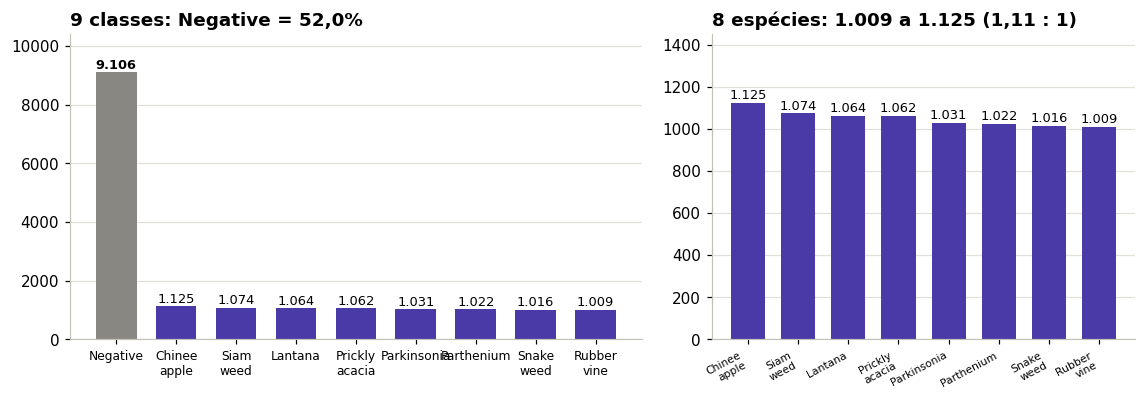

8 espécies : mín = 1.009 (Rubber vine) | máx = 1.125 (Chinee apple) | razão = 1,11 : 1
Negative   : 9.106 = 52,0% do total | 8,67× uma espécie média | 9,02× a menor
Baseline ingênuo (sempre responder 'Negative'): acurácia = 52,0%


In [8]:
cnt = df.species.value_counts()
species = [c for c in classes if c != "Negative"]
sp_cnt = cnt[species]
order = ["Negative"] + sp_cnt.sort_values(ascending=False).index.tolist()

fig = plt.figure(figsize=(12.5, 3.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1], wspace=0.14)
ax = fig.add_subplot(gs[0])
ax.bar(range(len(order)), [cnt[k] for k in order], width=0.68, color=[kind_c(k) for k in order])
for i, k in enumerate(order):
    ax.text(i, cnt[k] + 130, br(cnt[k]), ha="center", fontsize=8.5, fontweight="bold" if i == 0 else "normal")
ax.set_xticks(range(len(order))); ax.set_xticklabels([k.replace(" ", "\n") for k in order], fontsize=8)
ax.set_ylim(0, 10400); ax.yaxis.grid(True, color="#e1e0d9"); ax.set_axisbelow(True)
ax.set_title(f"9 classes: Negative = {pc(cnt['Negative'] / len(df))}")

ax = fig.add_subplot(gs[1])
ax.bar(range(len(species)), sp_cnt.sort_values(ascending=False).values, width=0.68, color=C_SPECIES)
for i, v in enumerate(sp_cnt.sort_values(ascending=False).values):
    ax.text(i, v + 20, br(v), ha="center", fontsize=8.5)
ax.set_xticks(range(len(species)))
ax.set_xticklabels([k.replace(" ", "\n") for k in sp_cnt.sort_values(ascending=False).index], fontsize=7, rotation=28, ha="right")
ax.set_ylim(0, 1450); ax.yaxis.grid(True, color="#e1e0d9"); ax.set_axisbelow(True)
ax.set_title(f"8 espécies: {br(sp_cnt.min())} a {br(sp_cnt.max())} ({num(sp_cnt.max() / sp_cnt.min(), 2)} : 1)")
plt.show()

print(f"8 espécies : mín = {br(sp_cnt.min())} ({sp_cnt.idxmin()}) | máx = {br(sp_cnt.max())} ({sp_cnt.idxmax()}) | razão = {num(sp_cnt.max() / sp_cnt.min(), 2)} : 1")
print(f"Negative   : {br(cnt['Negative'])} = {pc(cnt['Negative'] / len(df))} do total | {num(cnt['Negative'] / sp_cnt.mean())}× uma espécie média | {num(cnt['Negative'] / sp_cnt.min())}× a menor")
print(f"Baseline ingênuo (sempre responder 'Negative'): acurácia = {pc(cnt['Negative'] / len(df))}")

**Resposta:** só as **8 espécies estão balanceadas**. Com **Negative**, **não**: ela sozinha é mais da metade do dataset, e um modelo que responda sempre "Negative" já acertaria ~52% sem aprender nada. A acurácia sozinha engana.

**Como tratar** (sem alterar Validation/Test, que devem refletir o mundo real):

1. **Pesos de classe na loss**, `n_total / (n_classes · n_classe)` calculado só no Train (valores abaixo).
2. **Métricas por classe:** recall e F1 de cada espécie, **F1 macro** e matriz de confusão.
3. **Sem undersampling agressivo**: descartaria milhares de fotos de vegetação real, que ensinam à rede o que *não* é espécie-alvo. *Data augmentation* só no Train.
4. **Se os pesos não bastarem:** *oversampling* das espécies ou *focal loss* (a testar no treino).

In [9]:
class_weight = balanced_class_weights(df[df.split == "train"].species.tolist())
pd.Series({k: round(class_weight[k], 3) for k in classes}, name="class_weight (Train)").to_frame().T

,Chinee apple,Lantana,Parkinsonia,Parthenium,Prickly acacia,Rubber vine,Siam weed,Snake weed,Negative
class_weight (Train),1.728,1.828,1.886,1.905,1.833,1.929,1.811,1.915,0.214


## 5. Medição das imagens

Uma única passada lê cada imagem e registra: **formato, modo (canais), largura, altura**, o **histograma de 256 níveis por canal RGB** e o histograma da versão já recortada (crop 224). Com os histogramas obtenho média, desvio-padrão e intervalo dos pixels **exatos** de cada conjunto, sem guardar as imagens na memória.

In [10]:
BINS = np.arange(256)


def hist_rgb(arr):
    return np.stack([np.bincount(arr[..., c].ravel(), minlength=256) for c in range(3)])


def moments(h):
    # média e desvio-padrão por canal (escala 0-255) a partir de histogramas (3, 256)
    n = h.sum(axis=1)
    mean = (h * BINS).sum(axis=1) / n
    var = (h * BINS**2).sum(axis=1) / n - mean**2
    return mean, np.sqrt(var)


def analyse(path):
    with Image.open(path) as im:
        fmt, mode = im.format, im.mode
    img = load_rgb(path)                                   # sempre 3 canais
    h_nat = hist_rgb(np.asarray(img))                      # pixels originais (256×256)
    h_pre = hist_rgb(np.asarray(center_crop(img, SIZE)))   # pixels que a CNN recebe em Val/Test
    mean, _ = moments(h_nat)
    all_mean = mean.mean()
    all_var = (h_nat.sum(axis=0) * BINS**2).sum() / h_nat.sum() - all_mean**2
    return {"format": fmt, "mode": mode, "width": img.width, "height": img.height,
            "brightness": 0.299 * mean[0] + 0.587 * mean[1] + 0.114 * mean[2],
            "contrast": float(np.sqrt(all_var)), "h_nat": h_nat, "h_pre": h_pre}


t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    rows = list(ex.map(analyse, paths))
print(f"{br(len(rows))} imagens analisadas em {time.time() - t0:.0f}s")

hn = np.stack([r.pop("h_nat") for r in rows])
hp = np.stack([r.pop("h_pre") for r in rows])
df = pd.concat([df, pd.DataFrame(rows)], axis=1)

mask = {s: (df.split == s).to_numpy() for s in SPLITS}
H_nat = {s: hn[m].sum(axis=0) for s, m in mask.items()}   # histogramas por split (pixels originais)
H_pre = {s: hp[m].sum(axis=0) for s, m in mask.items()}   # histogramas por split (após o crop 224)
df[["file", "species", "split", "format", "mode", "width", "height", "brightness", "contrast"]].head()

17.509 imagens analisadas em 40s


,file,species,split,format,mode,width,height,brightness,contrast
0,20160928-140314-0.jpg,Chinee apple,train,JPEG,RGB,256,256,80.611247,62.270069
1,20160928-140337-0.jpg,Chinee apple,val,JPEG,RGB,256,256,71.139254,46.272920
2,20160928-140731-0.jpg,Chinee apple,train,JPEG,RGB,256,256,87.826166,52.662476
3,20160928-140747-0.jpg,Chinee apple,train,JPEG,RGB,256,256,71.330282,53.138574
4,20160928-141107-0.jpg,Chinee apple,train,JPEG,RGB,256,256,82.410357,64.116780


## 6. Comparação entre Train, Validation e Test

> O objetivo **não** é deixar os três conjuntos artificialmente idênticos, e sim verificar se **não há diferenças visuais grandes** que atrapalhem o treino e a avaliação.

### 6.1 Distribuição das classes

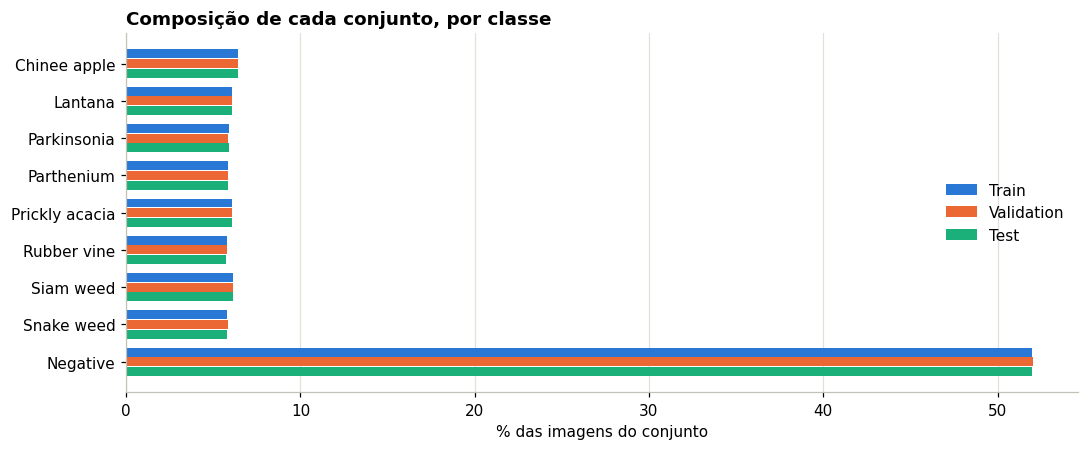

χ² classe  × conjunto: χ² = 0.026, p = 1.000
χ² câmera  × conjunto: χ² = 5.887, p = 0.660
p alto = não há evidência de que a composição difira entre os conjuntos.


In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
h = 0.24
for i, cls in enumerate(classes):
    for j, s in enumerate(SPLITS):
        d = df[df.split == s]
        v = (d.species == cls).mean() * 100
        ax.barh(i + (j - 1) * (h + 0.02), v, height=h, color=SPLIT_C[s], label=SPLIT_N[s] if i == 0 else None)
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes); ax.invert_yaxis()
ax.set_xlabel("% das imagens do conjunto"); ax.xaxis.grid(True, color="#e1e0d9"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="center right"); ax.set_title("Composição de cada conjunto, por classe")
plt.tight_layout(); plt.show()

chi_cls = stats.chi2_contingency(pd.crosstab(df.split, df.species))
chi_inst = stats.chi2_contingency(pd.crosstab(df.split, df.instrument))
print(f"χ² classe  × conjunto: χ² = {chi_cls[0]:.3f}, p = {chi_cls[1]:.3f}")
print(f"χ² câmera  × conjunto: χ² = {chi_inst[0]:.3f}, p = {chi_inst[1]:.3f}")
print("p alto = não há evidência de que a composição difira entre os conjuntos.")

### 6.2 Média, desvio-padrão e intervalo dos pixels

R     G     B  min  max
Train      média   96.5  99.3  96.8    0  255
           desvio  60.2  59.9  59.3    0  255
Validation média   96.6  99.2  96.7    0  255
           desvio  60.2  59.8  59.2    0  255
Test       média   96.9  99.5  97.0    0  255
           desvio  59.8  59.5  58.9    0  255

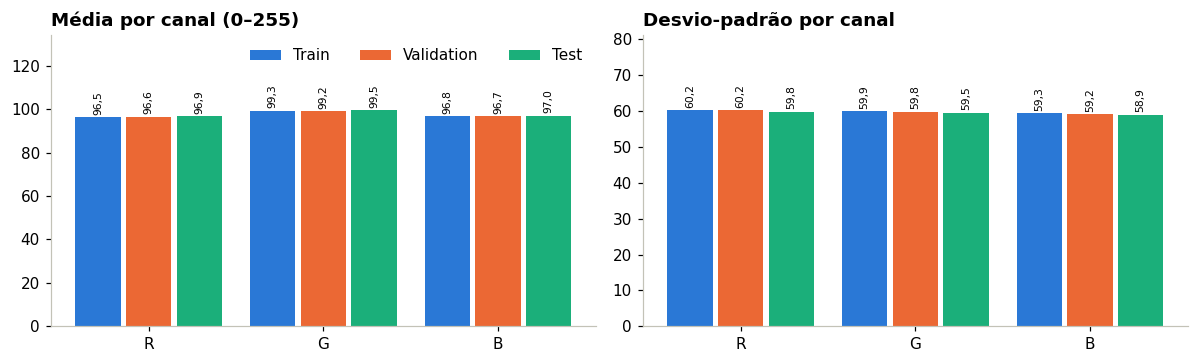

In [12]:
px = {}
for s in SPLITS:
    mean, std = moments(H_nat[s])
    present = np.nonzero(H_nat[s].sum(axis=0))[0]
    px[s] = {"mean": mean, "std": std, "min": present.min(), "max": present.max()}

tbl = pd.DataFrame({
    (SPLIT_N[s], m): [px[s][k][c] for c in range(3)] for s in SPLITS for m, k in (("média", "mean"), ("desvio", "std"))
}, index=["R", "G", "B"]).round(1).T
tbl["min"] = [px[s]["min"] for s in SPLITS for _ in range(2)]
tbl["max"] = [px[s]["max"] for s in SPLITS for _ in range(2)]
display(tbl)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, key, title in ((axes[0], "mean", "Média por canal (0–255)"), (axes[1], "std", "Desvio-padrão por canal")):
    w, top = 0.26, max(px[s][key].max() for s in SPLITS)
    for j, s in enumerate(SPLITS):
        xs = np.arange(3) + (j - 1) * (w + 0.03)
        ax.bar(xs, px[s][key], width=w, color=SPLIT_C[s], label=SPLIT_N[s])
        for x, v in zip(xs, px[s][key]):
            ax.text(x, v + top * 0.02, num(v, 1), ha="center", fontsize=7, rotation=90)
    ax.set_xticks(range(3)); ax.set_xticklabels(["R", "G", "B"]); ax.set_title(title); ax.set_ylim(0, top * 1.35)
axes[0].legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

### 6.3 Histogramas de intensidade por canal RGB

Em cima, o histograma de cada conjunto (faixas de 4 níveis, em % dos pixels). Embaixo, a **diferença** de Validation e Test em relação ao Train, em pontos percentuais.

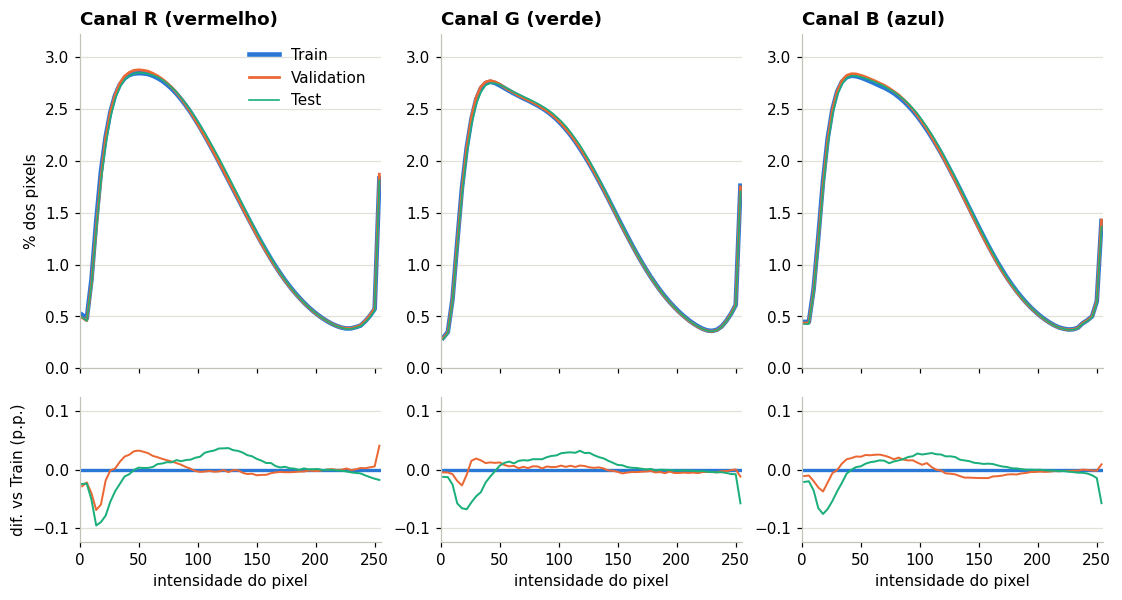

Maior diferença de histograma vs Train: 0,095 ponto percentual por faixa de 4 níveis


In [13]:
x = np.arange(64) * 4 + 2
def norm_hist(s, c):
    hh = H_nat[s][c].astype(float)
    return hh.reshape(64, 4).sum(axis=1) / hh.sum() * 100

ymax = max(norm_hist(s, c).max() for s in SPLITS for c in range(3)) * 1.12
dmax = max(np.abs(norm_hist(s, c) - norm_hist("train", c)).max() for s in ("val", "test") for c in range(3))
fig, axes = plt.subplots(2, 3, figsize=(12, 6), gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.12})
for c, name in enumerate(["Canal R (vermelho)", "Canal G (verde)", "Canal B (azul)"]):
    top, bot = axes[0, c], axes[1, c]
    for s, lw in (("train", 3.0), ("val", 1.8), ("test", 1.1)):
        top.plot(x, norm_hist(s, c), color=SPLIT_C[s], lw=lw, label=SPLIT_N[s])
    top.set_title(name); top.set_xlim(0, 255); top.set_ylim(0, ymax); top.tick_params(labelbottom=False)
    top.yaxis.grid(True, color="#e1e0d9"); top.set_axisbelow(True)
    bot.axhline(0, color=SPLIT_C["train"], lw=2.2)
    for s in ("val", "test"):
        bot.plot(x, norm_hist(s, c) - norm_hist("train", c), color=SPLIT_C[s], lw=1.3)
    bot.set_xlim(0, 255); bot.set_ylim(-dmax * 1.3, dmax * 1.3); bot.set_xlabel("intensidade do pixel")
    bot.yaxis.grid(True, color="#e1e0d9"); bot.set_axisbelow(True)
    if c == 0:
        top.set_ylabel("% dos pixels"); bot.set_ylabel("dif. vs Train (p.p.)")
axes[0, 0].legend(frameon=False)
plt.show()
print(f"Maior diferença de histograma vs Train: {num(dmax, 3)} ponto percentual por faixa de 4 níveis")

### 6.4 Testes de semelhança

* **KS de duas amostras** no *brilho médio* e no *contraste* (desvio-padrão) de cada imagem. **D** é a distância máxima entre as curvas acumuladas (0 = idênticas); com milhares de imagens o p-valor é muito sensível, então D é a medida de tamanho do efeito.
* **Distância de Wasserstein** entre os histogramas RGB, em **níveis de intensidade** (de 0 a 255).

In [14]:
pairs = [("train", "val"), ("train", "test"), ("val", "test")]
rows_ = []
for a, b in pairs:
    da, db = df[df.split == a], df[df.split == b]
    ks_b = stats.ks_2samp(da.brightness, db.brightness)
    ks_c = stats.ks_2samp(da.contrast, db.contrast)
    w1 = [stats.wasserstein_distance(BINS, BINS, H_nat[a][c], H_nat[b][c]) for c in range(3)]
    rows_.append({"par": f"{SPLIT_N[a]} × {SPLIT_N[b]}",
                  "KS brilho D": ks_b.statistic, "p (brilho)": ks_b.pvalue,
                  "KS contraste D": ks_c.statistic, "p (contraste)": ks_c.pvalue,
                  "Wasserstein R": w1[0], "G": w1[1], "B": w1[2],
                  "Δ média RGB máx (de 255)": np.abs(px[a]["mean"] - px[b]["mean"]).max()})
cmp_tbl = pd.DataFrame(rows_).set_index("par").round(3)
display(cmp_tbl)

,KS brilho D,p (brilho),KS contraste D,p (contraste),Wasserstein R,G,B,Δ média RGB máx (de 255)
par,,,,,,,,
Train × Validation,0.018,0.498,0.010,0.978,0.169,0.158,0.225,0.131
Train × Test,0.019,0.434,0.018,0.453,0.532,0.424,0.426,0.396
Validation × Test,0.027,0.280,0.023,0.493,0.516,0.409,0.486,0.333


**Leitura:** as curvas dos três conjuntos praticamente coincidem nos 3 canais, e as diferenças não passam de ≈ 0,1 ponto percentual por faixa. O KS dá D muito pequeno e a maior diferença entre médias RGB é de menos de 1 nível em 255. **Não há sinal de que Validation ou Test tenham um "visual" diferente do Train.** Uma ressalva importante, sobre *por que* são tão parecidos, vem na seção 7.

## 7. Dimensão das imagens, câmeras e sessões de captura

In [15]:
print("Formato real dos arquivos :", dict(Counter(df.format)))
print("Modo (canais)             :", dict(Counter(df["mode"])))
print("Tamanhos distintos        :", dict(Counter(zip(df.width, df.height))))
print("Tamanho por conjunto      :", {SPLIT_N[s]: dict(Counter(zip(df[df.split == s].width, df[df.split == s].height))) for s in SPLITS})
print("Intervalo dos pixels      :", {SPLIT_N[s]: (int(px[s]["min"]), int(px[s]["max"])) for s in SPLITS})
print("Câmeras (ID no nome)      :", dict(sorted(Counter(df.instrument).items())), "(a documentação cita 0–3)")
print(f"Sessões (data + câmera)   : {df.session.nunique()} em {df.date.nunique()} datas, de {df.date.min()} a {df.date.max()}")

Formato real dos arquivos : {'JPEG': 17509}
Modo (canais)             : {'RGB': 17509}
Tamanhos distintos        : {(256, 256): 17509}
Tamanho por conjunto      : {'Train': {(256, 256): 12256}, 'Validation': {(256, 256): 2626}, 'Test': {(256, 256): 2627}}
Intervalo dos pixels      : {'Train': (0, 255), 'Validation': (0, 255), 'Test': (0, 255)}
Câmeras (ID no nome)      : {0: 2413, 1: 5423, 2: 6354, 3: 3292, 4: 27} (a documentação cita 0–3)
Sessões (data + câmera)   : 101 em 60 datas, de 20160928 a 20180322


**Leitura:** **todas as imagens têm o mesmo tamanho (256×256), 3 canais RGB e pixels de 0 a 255**, então não há variação de resolução a corrigir. O que varia é a **sessão de captura** (data + câmera), e é aí que mora um risco: se a espécie estiver muito ligada a poucas sessões, a CNN pode aprender o *fundo*, e não a planta.

### 7.1 Quão concentrada é cada espécie em poucas sessões?

In [16]:
sess = df.groupby("species").session.nunique().reindex(classes)
top_share = df.groupby(["species", "session"]).size().groupby(level=0).apply(lambda s: s.max() / s.sum()).reindex(classes)
display(pd.DataFrame({"imagens": cnt.reindex(classes), "sessões": sess, "% na maior sessão": (top_share * 100).round(1)}))

,imagens,sessões,% na maior sessão
species,,,
Chinee apple,1125,23,16.4
Lantana,1064,16,17.0
Parkinsonia,1031,6,24.2
Parthenium,1022,9,21.1
Prickly acacia,1062,16,30.7
Rubber vine,1009,11,23.5
Siam weed,1074,8,25.7
Snake weed,1016,21,16.4
Negative,9106,53,9.4


### 7.2 Split por sessão: testado e descartado

Para evitar esse vazamento, o ideal seria colocar **sessões inteiras** em um só conjunto. Testo isso com `StratifiedGroupKFold` (grupo = sessão, estratificado por classe; 20 dobras de ~5%: 14 para Train, 3 para Val, 3 para Test) em 4 sementes:

In [17]:
from sklearn.model_selection import StratifiedGroupKFold


def group_split(df, seed, n_folds=20):
    fold = np.zeros(len(df), int)
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for i, (_, te) in enumerate(sgkf.split(df, df.label, groups=df.session)):
        fold[te] = i
    return np.where(fold < 14, "train", np.where(fold < 17, "val", "test"))


res_ = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for seed in (42, 0, 1, 7):
        g = group_split(df, seed)
        t = pd.crosstab(pd.Series(g, name="split"), df.species).reindex(SPLITS)
        frac = t.loc[["val", "test"]] / t.sum()
        worst = frac.stack().idxmin()
        res_.append({"seed": seed, "% train/val/test": " / ".join(pc(v / len(df), 0) for v in t.sum(axis=1)),
                     "classes sem nenhuma imagem em Val/Test": ", ".join(f"{c} ({s})" for s in ("val", "test") for c in t.columns if t.loc[s, c] == 0) or "nenhuma",
                     "pior caso (fração da classe)": f"{worst[1]} em {worst[0]}: {pc(frac.stack().min(), 1)}  (alvo: 15%)"})
display(pd.DataFrame(res_).set_index("seed"))

,% train/val/test,classes sem nenhuma imagem em Val/Test,pior caso (fração da classe)
seed,,,
42,67% / 16% / 17%,Lantana (test),"Lantana em test: 0,0% (alvo: 15%)"
0,67% / 16% / 17%,Lantana (test),"Lantana em test: 0,0% (alvo: 15%)"
1,67% / 16% / 17%,Lantana (test),"Lantana em test: 0,0% (alvo: 15%)"
7,67% / 16% / 17%,Lantana (test),"Lantana em test: 0,0% (alvo: 15%)"


**Conclusão:** cada espécie está concentrada em poucas sessões grandes, então dividir *por sessão* deixa classes sem nenhuma imagem (ou quase) em Validation ou Test, e o split perde o sentido. **Mantive o split estratificado por classe**, que é o mesmo protocolo (aleatório) do artigo original da DeepWeeds, e passo a **medir e declarar o risco**:

### 7.3 Quão perto, no tempo, está cada foto de Val/Test de uma foto de Train?

Fotos de Val/Test                                  : 5.253
... com foto de Train da mesma sessão e classe     : 99,8%
... a no máximo   5 s de uma foto de Train            : 6,3%
... a no máximo  30 s de uma foto de Train            : 81,8%
... a no máximo  60 s de uma foto de Train            : 93,5%
... a no máximo 300 s de uma foto de Train            : 98,9%
Mediana da distância no tempo                      : 15 s


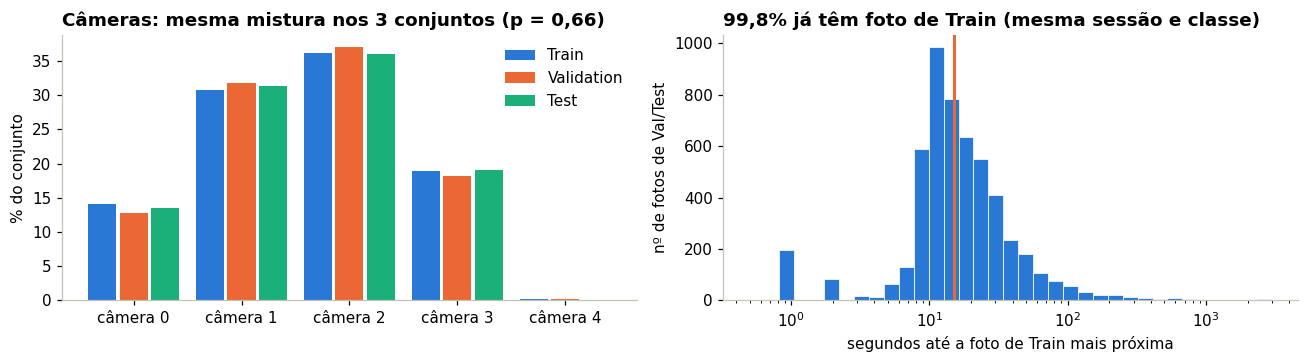

In [18]:
gaps = nearest_train_gap(df)                  # segundos até a foto de Train mais próxima (mesma sessão e classe)
ev = gaps[~np.isnan(gaps)]
fin = ev[np.isfinite(ev)]
print(f"Fotos de Val/Test                                  : {br(len(ev))}")
print(f"... com foto de Train da mesma sessão e classe     : {pc(np.isfinite(ev).mean())}")
for lim in (5, 30, 60, 300):
    print(f"... a no máximo {lim:>3} s de uma foto de Train            : {pc((ev <= lim).mean())}")
print(f"Mediana da distância no tempo                      : {np.median(fin):.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axes[0]
for j, s in enumerate(SPLITS):
    v = [(df[df.split == s].instrument == i).mean() * 100 for i in sorted(df.instrument.unique())]
    ax.bar(np.arange(len(v)) + (j - 1) * 0.29, v, width=0.26, color=SPLIT_C[s], label=SPLIT_N[s])
ax.set_xticks(range(len(v))); ax.set_xticklabels([f"câmera {i}" for i in sorted(df.instrument.unique())])
ax.set_ylabel("% do conjunto"); ax.set_title(f"Câmeras: mesma mistura nos 3 conjuntos (p = {num(chi_inst[1], 2)})"); ax.legend(frameon=False)
ax = axes[1]
ax.hist(np.clip(fin, 0.5, 3000), bins=np.logspace(np.log10(0.5), np.log10(3000), 36), color=SPLIT_C["train"], edgecolor="white", lw=0.5)
ax.set_xscale("log"); ax.axvline(np.median(fin), color=SPLIT_C["val"], lw=2)
ax.set_xlabel("segundos até a foto de Train mais próxima"); ax.set_ylabel("nº de fotos de Val/Test")
ax.set_title(f"{pc(np.isfinite(ev).mean())} já têm foto de Train (mesma sessão e classe)")
plt.tight_layout(); plt.show()

**Leitura:** quase todas as fotos de Validation e Test têm uma foto de Train da **mesma sessão e classe**, tirada em geral poucas dezenas de segundos antes ou depois. Não são cópias (nenhuma duplicata exata), mas dividem cenário, luz e câmera. Por isso os conjuntos são tão parecidos, e por isso a acurácia no Test tende a ser **otimista para locais novos**. Isso não invalida o dataset para o treino, mas precisa constar na avaliação final.

## 8. Padronização para a CNN

**Entrada escolhida: `224 × 224 × 3`**, tamanho padrão de backbones pré-treinados e o protocolo do artigo original (imagem 256 → crop 224).

Como todas as imagens já são **quadradas e do mesmo tamanho (256×256)**:

| Etapa | Decisão | Motivo |
|---|---|---|
| **Resize** | não necessário | não há tamanhos diferentes para uniformizar |
| **Padding** | não necessário | imagem quadrada: sem barras a completar, sem distorção |
| **Crop 224 × 224** | **Train:** posição aleatória + espelho horizontal (augmentation). **Val/Test:** centro | recorte *sem reamostrar*: Train e Val/Test ficam na mesma escala de pixel |
| **Normalização** | `x/255` → `(x − μ)/σ` por canal, com μ e σ do **Train** | sem vazamento de Val/Test |

Alternativa considerada: `resize 256 → 224`, que perde 0% da área mas reamostra (×0,875). O `center crop` custa uma fração da área nas bordas em Val/Test; o crop aleatório no Train expõe essas bordas à rede.

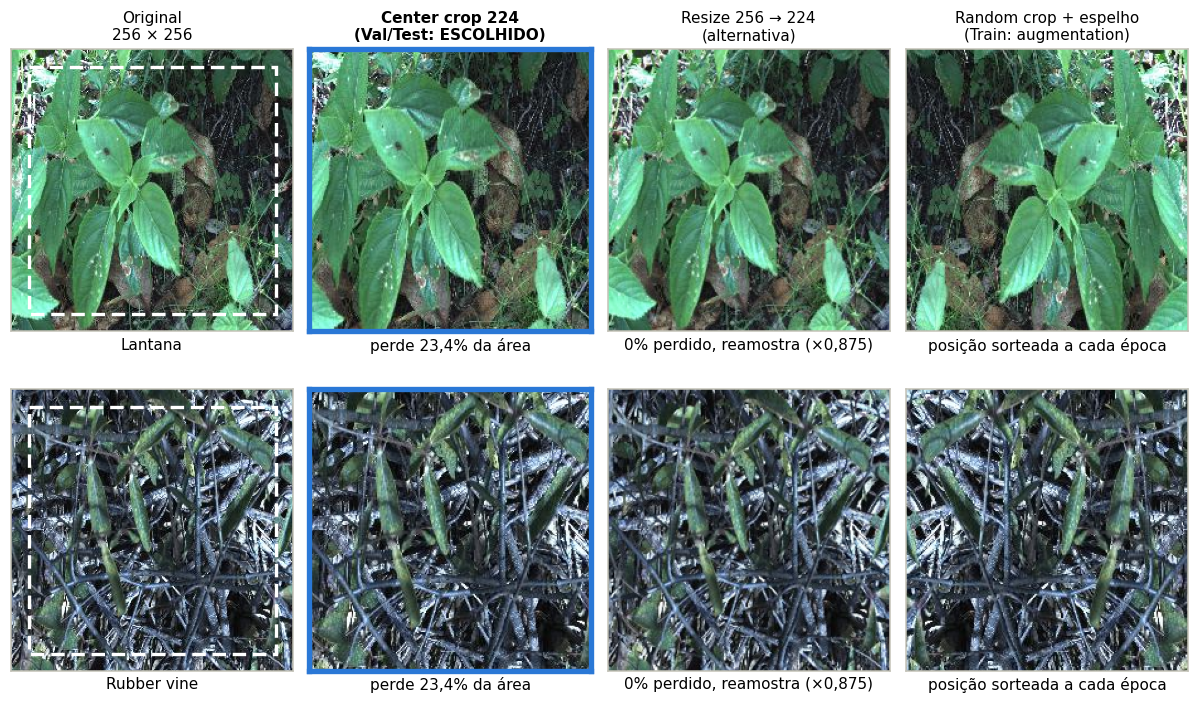

Área descartada pelo center crop 224 a partir de 256: 23,4%


In [19]:
tr_ = df[df.split == "train"].sort_values("file")
picks = [tr_[tr_.species == "Lantana"].iloc[4], tr_[tr_.species == "Rubber vine"].iloc[9]]
lost = crop_area_lost(int(df.width.iloc[0]), SIZE)
cols = ["Original\n256 × 256", "Center crop 224\n(Val/Test: ESCOLHIDO)", "Resize 256 → 224\n(alternativa)", "Random crop + espelho\n(Train: augmentation)"]

rng = np.random.default_rng(11)
fig, axes = plt.subplots(2, 4, figsize=(11, 6.2))
for r, row in enumerate(picks):
    img = load_rgb(IMAGES / row.file)
    outs = [img, center_crop(img, SIZE), img.resize((SIZE, SIZE), Image.BICUBIC), ImageOps.mirror(random_crop(img, SIZE, rng))]
    for c, o in enumerate(outs):
        ax = axes[r, c]; ax.imshow(o); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(SPLIT_C["train"] if c == 1 else "#c3c2b7"); s.set_linewidth(3.5 if c == 1 else 1)
        if r == 0:
            ax.set_title(cols[c], fontsize=10, fontweight="bold" if c == 1 else "normal", loc="center")
    axes[r, 0].add_patch(Rectangle((16, 16), SIZE, SIZE, fill=False, edgecolor="white", lw=2.2, ls=(0, (4, 2))))
    axes[r, 0].set_xlabel(row.species)
    axes[r, 1].set_xlabel(f"perde {pc(lost)} da área")
    axes[r, 2].set_xlabel("0% perdido, reamostra (×0,875)")
    axes[r, 3].set_xlabel("posição sorteada a cada época")
plt.tight_layout(); fig.subplots_adjust(hspace=0.2); plt.show()
print(f"Área descartada pelo center crop 224 a partir de 256: {pc(lost)}")

### Normalização

`x / 255` leva os pixels a `[0, 1]`; depois `(x − μ) / σ` por canal centraliza e escala os dados, o que estabiliza e acelera o treino. **μ e σ são calculados só no Train** (usar Validation/Test aqui vazaria informação), nas imagens **já recortadas** (a entrada real da CNN).

In [20]:
tr_mean, tr_std = moments(H_pre["train"])
MEAN, STD = tr_mean / 255, tr_std / 255
IMAGENET_MEAN, IMAGENET_STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

print("Constantes de normalização (só do Train, imagens 224×224)")
print("  MEAN =", np.round(MEAN, 4), "   ImageNet:", IMAGENET_MEAN)
print("  STD  =", np.round(STD, 4), "   ImageNet:", IMAGENET_STD)
print("  As fotos são mais escuras que as do ImageNet (MEAN menor). Com backbone pré-treinado, usar as constantes do ImageNet.\n")

chk = []
for s in SPLITS:
    m, sd = moments(H_pre[s])
    chk.append({"conjunto": SPLIT_N[s],
                **{f"μ {ch}": v for ch, v in zip("RGB", (m / 255 - MEAN) / STD)},
                **{f"σ {ch}": v for ch, v in zip("RGB", (sd / 255) / STD)}})
print("Após normalizar com as constantes do Train (esperado: μ ≈ 0 e σ ≈ 1):")
display(pd.DataFrame(chk).set_index("conjunto").round(3))

Constantes de normalização (só do Train, imagens 224×224)
  MEAN = [0.3758 0.3879 0.3769]    ImageNet: [0.485 0.456 0.406]
  STD  = [0.2342 0.2334 0.2307]    ImageNet: [0.229 0.224 0.225]
  As fotos são mais escuras que as do ImageNet (MEAN menor). Com backbone pré-treinado, usar as constantes do ImageNet.

Após normalizar com as constantes do Train (esperado: μ ≈ 0 e σ ≈ 1):


,μ R,μ G,μ B,σ R,σ G,σ B
conjunto,,,,,,
Train,0.000,0.000,0.000,1.000,1.000,1.000
Validation,0.001,-0.003,-0.003,0.999,0.997,0.997
Test,0.006,0.003,0.003,0.994,0.994,0.993


In [21]:
# Pipelines completos, de ponta a ponta: imagem original -> crop -> normalização -> tensor para a CNN
def eval_transform(path, mean=MEAN, std=STD, size=SIZE):
    img = load_rgb(path)                                   # 3 canais garantidos
    return normalize(np.asarray(center_crop(img, size)), mean, std)          # Val / Test


def train_transform(path, rng, mean=MEAN, std=STD, size=SIZE):
    img = random_crop(load_rgb(path), size, rng)           # posição aleatória
    if rng.random() < 0.5:
        img = ImageOps.mirror(img)                         # espelho horizontal
    return normalize(np.asarray(img), mean, std)


rng = np.random.default_rng(SEED)
val_paths = [IMAGES / f for f in df[df.split == "val"].file.head(8)]
batch_eval = np.stack([eval_transform(p) for p in val_paths])
batch_train = np.stack([train_transform(p, rng) for p in val_paths])
print("batch Val/Test (N, H, W, C):", batch_eval.shape, "| dtype:", batch_eval.dtype)
print("batch Train    (N, H, W, C):", batch_train.shape)
print("μ por canal (8 imgs):", np.round(batch_eval.reshape(-1, 3).mean(0), 3), "| σ:", np.round(batch_eval.reshape(-1, 3).std(0), 3))
print("Obs.: com só 8 imagens, μ e σ do lote não são exatamente 0 e 1; isso só vale para o conjunto inteiro (tabela acima).")
print("Para PyTorch (N, C, H, W):", np.transpose(batch_eval, (0, 3, 1, 2)).shape)

batch Val/Test (N, H, W, C): (8, 224, 224, 3) | dtype: float32
batch Train    (N, H, W, C): (8, 224, 224, 3)
μ por canal (8 imgs): [-0.338 -0.207 -0.377] | σ: [0.943 1.01  0.959]
Obs.: com só 8 imagens, μ e σ do lote não são exatamente 0 e 1; isso só vale para o conjunto inteiro (tabela acima).
Para PyTorch (N, C, H, W): (8, 3, 224, 224)


## 9. Análise final

As quatro perguntas do sprint, respondidas com os números calculados acima.

In [22]:
mean_diff = cmp_tbl["Δ média RGB máx (de 255)"].max()
ks_D = cmp_tbl[["KS brilho D", "KS contraste D"]].to_numpy().max()
ks_p_min = cmp_tbl[["p (brilho)", "p (contraste)"]].to_numpy().min()
post = pd.DataFrame(chk).set_index("conjunto").loc[["Validation", "Test"]]
post_mu = post[[c for c in post.columns if c.startswith("μ")]].abs().to_numpy().max()
post_sd = post[[c for c in post.columns if c.startswith("σ")]].to_numpy()
w_sp = [class_weight[k] for k in species]

display(Markdown(f"""
### 1. O dataset está balanceado?
**Parcialmente.** Só as **8 espécies**, sim: {br(sp_cnt.min())} a {br(sp_cnt.max())} imagens (razão {num(sp_cnt.max() / sp_cnt.min(), 2)} : 1).
Com **Negative**, não: {br(cnt['Negative'])} imagens = {pc(cnt['Negative'] / len(df))} do total.
**Tratamento:** pesos de classe (Negative ≈ {num(class_weight['Negative'])}; espécies ≈ {num(min(w_sp))}–{num(max(w_sp))}), F1 macro e recall por classe, sem undersampling agressivo.

### 2. Train, Validation e Test têm características semelhantes?
**Sim.** Composição de classes idêntica (χ² p = {num(chi_cls[1], 2)}) e mesma mistura de câmeras (p = {num(chi_inst[1], 2)}); médias RGB a no máximo {up(mean_diff, 1)} nível de 255;
KS com D ≤ {up(ks_D, 3)} (p ≥ {down(ks_p_min, 2)}); histogramas RGB sobrepostos e intervalo de pixels idêntico (0–255).
**Ressalva:** essa semelhança é em boa parte porque o split é aleatório e divide as *mesmas sessões* entre os conjuntos ({pc(np.isfinite(ev).mean())} das fotos de Val/Test têm foto de Train da mesma sessão e classe; mediana de {np.median(fin):.0f} s).

### 3. As imagens estão adequadamente padronizadas?
**Sim.** Todas RGB e 256×256; a entrada da CNN é **{SIZE}×{SIZE}×3 (float32)** via crop (aleatório no Train, central em Val/Test), sem resize nem padding, e normalização com μ e σ do Train.
Após normalizar, Validation e Test ficam com |μ| ≤ {up(post_mu, 3)} e σ entre {down(post_sd.min(), 3)} e {up(post_sd.max(), 3)}.

### 4. O dataset está pronto para o treinamento de uma CNN?
**Sim, com 3 cuidados:**
1. Aplicar **pesos de classe** e acompanhar **F1 macro** e o recall de cada espécie, não só a acurácia.
2. Usar o **Test uma única vez**, no final, sabendo que ele divide sessões com o Train: a acurácia tende a ser otimista para locais novos.
3. **Analisar os erros por câmera/sessão**: espécie e local estão associados (ex.: Parkinsonia aparece em só {sess['Parkinsonia']} sessões), e a CNN pode estar usando o fundo.
"""))


### 1. O dataset está balanceado?
**Parcialmente.** Só as **8 espécies**, sim: 1.009 a 1.125 imagens (razão 1,11 : 1).
Com **Negative**, não: 9.106 imagens = 52,0% do total.
**Tratamento:** pesos de classe (Negative ≈ 0,21; espécies ≈ 1,73–1,93), F1 macro e recall por classe, sem undersampling agressivo.

### 2. Train, Validation e Test têm características semelhantes?
**Sim.** Composição de classes idêntica (χ² p = 1,00) e mesma mistura de câmeras (p = 0,66); médias RGB a no máximo 0,4 nível de 255;
KS com D ≤ 0,027 (p ≥ 0,28); histogramas RGB sobrepostos e intervalo de pixels idêntico (0–255).
**Ressalva:** essa semelhança é em boa parte porque o split é aleatório e divide as *mesmas sessões* entre os conjuntos (99,8% das fotos de Val/Test têm foto de Train da mesma sessão e classe; mediana de 15 s).

### 3. As imagens estão adequadamente padronizadas?
**Sim.** Todas RGB e 256×256; a entrada da CNN é **224×224×3 (float32)** via crop (aleatório no Train, central em Val/Test), sem resize nem padding, e normalização com μ e σ do Train.
Após normalizar, Validation e Test ficam com |μ| ≤ 0,007 e σ entre 0,993 e 0,999.

### 4. O dataset está pronto para o treinamento de uma CNN?
**Sim, com 3 cuidados:**
1. Aplicar **pesos de classe** e acompanhar **F1 macro** e o recall de cada espécie, não só a acurácia.
2. Usar o **Test uma única vez**, no final, sabendo que ele divide sessões com o Train: a acurácia tende a ser otimista para locais novos.
3. **Analisar os erros por câmera/sessão**: espécie e local estão associados (ex.: Parkinsonia aparece em só 6 sessões), e a CNN pode estar usando o fundo.


---
**Arquivos gerados por este notebook:** `dataset/{train,val,test}/<Classe>/` (imagens separadas) e `splits.csv` (manifesto: arquivo, rótulo, espécie, sessão, split).
**Reprodutibilidade:** `SEED = 42`; a divisão é determinística.
**Fonte dos dados:** Olsen, A. et al. *DeepWeeds: A Multiclass Weed Species Image Dataset for Deep Learning.* Scientific Reports 9, 2058 (2019), CC BY 4.0. https://github.com/AlexOlsen/DeepWeeds